# 🧠 BÀI TẬP LỚN: PHÂN LOẠI TÍN HIỆU EEG ODDBALL (P300)
## MÔ HÌNH HỌC MÁY: ĐẶC TRƯNG MIỀN TẦN SỐ & PHI TUYẾN
**Thành viên thực hiện**: **Hồng Anh** (Nhóm 9 - AIT3012)

---
### 🎯 Mục Tiêu Đề Tài
1. **Bài toán**: Phân loại nhị phân 2 lớp kích thích thị giác trong Oddball Paradigm:
   - **Lớp 0 (Standard - Kích thích thường)**: Mã sự kiện `5` (tần suất xuất hiện cao ~80%).
   - **Lớp 1 (Target - Kích thích đích)**: Mã sự kiện `6` (kích thích hiếm ~10%, kích hoạt sóng P300).
   - *(Loại bỏ kích thích gây nhiễu Distractor mã 7).*
2. **Phân chia đối tượng độc lập (Subject-Independent)**:
   - **Tập Train (Người 1 - 28)**: 16.235 mẫu epoch.
   - **Tập Validation (Người 29 - 34)**: 3.474 mẫu epoch.
   - **Tập Test (Người 35 - 42)**: 4.731 mẫu epoch.
3. **Đặc trưng trích xuất**:
   - **Miền tần số**: Năng lượng phổ Welch PSD (5 dải sóng: $\delta, \theta, \alpha, \beta, \gamma$) + Tỉ số $\theta / \beta$.
   - **Miền phi tuyến**: Spectral Entropy (độ hỗn loạn phổ) + Bộ tham số Hjorth (Mobility & Complexity).
4. **Mô hình & So sánh**:
   - **Mô hình 1**: Logistic Regression (Tuyến tính, phạt L2, cân bằng trọng số `class_weight='balanced'`).
   - **Mô hình 2**: Random Forest Classifier (Tổ hợp cây quyết định phi tuyến).
   - **So sánh**: Bảng đối chiếu Accuracy, Balanced Accuracy, F1-Score, ROC-AUC và biểu đồ đường cong ROC.

### 1. Cài Đặt Thư Viện Cần Thiết
Cài đặt `mne`, `mne-bids` để nạp dữ liệu BrainVision chuẩn BIDS và các thư viện khoa học tính toán.

In [16]:
!pip install -q mne mne-bids scipy scikit-learn matplotlib seaborn

### 2. Khai Báo Thư Viện & Cấu Hình Đường Dẫn Dữ Liệu
Tự động nhận diện đường dẫn dữ liệu trên Kaggle hoặc máy tính cục bộ.

In [17]:
import os
import glob
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats, signal
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score
)

import mne
from mne_bids import BIDSPath, read_raw_bids

# Tự động tìm thư mục data trên Kaggle
possible_paths = list(Path("/kaggle/input").rglob("data"))
DATA_ROOT = possible_paths[0] if possible_paths else Path("/kaggle/input/nencki-symfonia-eeg-oddball/data")
CACHE_DIR = Path("/kaggle/working/cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Đường dẫn dữ liệu: {DATA_ROOT}")
print(f"Thư mục lưu cache: {CACHE_DIR}")

Đường dẫn dữ liệu: /kaggle/input/datasets/trungdttik55/nencki-symfonia-eeg-oddball/data
Thư mục lưu cache: /kaggle/working/cache


### 3. Hàm Tiền Xử Lý Sóng Não Theo Chuẩn BIDS (`preprocess_subject`)
- Áp dụng bộ lọc số: Notch Filter 50Hz (triệt tiêu nhiễu điện lưới) và Band-pass Filter 0.1 - 40Hz.
- Gán vị trí kênh điện cực (Montage `colin27_1005`) và Re-reference theo mức trung bình (Average Reference).
- Tách epoch: Cửa sổ $[-0.2, 0.8]\text{s}$, hiệu chỉnh baseline $[-0.2, 0]\text{s}$.

In [18]:
TASK = "oddball"
MONTAGE_NAME = "colin27_1005"
STIMULUS_EVENT_ID = {"standard": 5, "target": 6}

def preprocess_subject(subject_id: int):
    sub_str = f"{int(subject_id):02d}"
    bids_path = BIDSPath(subject=sub_str, task=TASK, datatype="eeg", root=str(DATA_ROOT))
    
    # 1. Đọc dữ liệu raw
    raw = read_raw_bids(bids_path=bids_path, verbose=False, on_ch_mismatch="warn")
    raw.load_data()
    raw.pick("eeg")
    
    # 2. Bộ lọc số: Notch 50Hz và Bandpass 0.1 - 40Hz
    raw.notch_filter(50.0, verbose=False)
    raw.filter(0.1, 40.0, verbose=False)
    
    # 3. Gán vị trí kênh (Montage) và Average Reference
    montage = mne.channels.make_standard_montage(MONTAGE_NAME)
    raw.set_montage(montage, on_missing="ignore")
    raw.set_eeg_reference("average", verbose=False)
    
    # 4. Đọc file sự kiện tsv
    events_path = DATA_ROOT / f"sub-{sub_str}" / "eeg" / f"sub-{sub_str}_task-{TASK}_events.tsv"
    events_tsv = pd.read_csv(events_path, sep="\t").dropna(subset=["trial_type"])
    
    event_codes = (
        events_tsv["event_type"]
        .str.replace(" ", "", regex=False)
        .str.extract(r"S(\d+)")[0]
        .astype(int)
    )
    events = np.column_stack([
        np.round(events_tsv["onset"].to_numpy() * raw.info["sfreq"]).astype(int),
        np.zeros(len(events_tsv), dtype=int),
        event_codes.to_numpy(),
    ])
    
    # Chỉ giữ lại Standard (5) và Target (6)
    target_events = events[np.isin(events[:, 2], [5, 6])]
    
    # Chia epochs: từ -0.2s đến 0.8s
    epochs = mne.Epochs(
        raw,
        target_events,
        event_id=STIMULUS_EVENT_ID,
        tmin=-0.2,
        tmax=0.8,
        baseline=(-0.2, 0),
        preload=True,
        verbose=False
    )
    return epochs

### 4. Trích Xuất Đặc Trưng Miền Tần Số & Phi Tuyến (Vectorized Feature Extraction)
- **Miền Tần Số**: Phổ công suất Welch cho 5 dải sóng $\delta$ (1-4Hz), $\theta$ (4-8Hz), $\alpha$ (8-12Hz), $\beta$ (12-30Hz), $\gamma$ (30-40Hz) và tỉ số $\theta / \beta$.
- **Miền Phi Tuyến**: Spectral Entropy $H_s = -\sum p_i \log_2(p_i)$ và bộ tham số hình thái Hjorth (Mobility & Complexity).
- Vector hóa bằng NumPy/SciPy: tốc độ tính toán chỉ mất vài giây cho hàng trăm epoch.

In [19]:
def extract_freq_and_nonlinear_features(epochs_data: np.ndarray, sfreq: float = 1000.0) -> np.ndarray:
    """
    epochs_data có shape: (N_epochs, N_channels, N_times) = (N, 127, 1001)
    Tính toán cực nhanh bằng ma trận NumPy & SciPy
    """
    # 1. MIỀN TẦN SỐ: Tính Mật độ phổ công suất (PSD) bằng phương pháp Welch
    freqs, psd = signal.welch(epochs_data, fs=sfreq, nperseg=min(256, epochs_data.shape[-1]), axis=-1)
    # psd có shape: (N, 127, N_freqs)
    
    # Tính năng lượng các dải tần sóng não (Band Power)
    def band_power(f_low, f_high):
        idx = (freqs >= f_low) & (freqs <= f_high)
        return np.mean(psd[:, :, idx], axis=-1)
    
    delta = band_power(1.0, 4.0)    # Sóng chậm Delta (1-4 Hz)
    theta = band_power(4.0, 8.0)    # Sóng Theta (4-8 Hz)
    alpha = band_power(8.0, 12.0)   # Sóng Alpha (8-12 Hz)
    beta  = band_power(12.0, 30.0)  # Sóng Beta (12-30 Hz)
    gamma = band_power(30.0, 40.0)  # Sóng Gamma chậm (30-40 Hz)
    
    # Tỉ số công suất đặc trưng trong nhận thức
    theta_beta_ratio = (theta + 1e-10) / (beta + 1e-10)
    
    # 2. MIỀN PHI TUYẾN:
    # A. Spectral Entropy (Độ hỗn loạn phổ tần số)
    psd_norm = psd / (np.sum(psd, axis=-1, keepdims=True) + 1e-10)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-10), axis=-1)
    
    # B. Bộ tham số phi tuyến Hjorth (Hjorth Mobility & Complexity)
    # Đạo hàm bậc 1 của tín hiệu theo thời gian (d1)
    d1 = np.diff(epochs_data, axis=-1)
    # Đạo hàm bậc 2 của tín hiệu theo thời gian (d2)
    d2 = np.diff(d1, axis=-1)
    
    var_zero = np.var(epochs_data, axis=-1) + 1e-10
    var_d1   = np.var(d1, axis=-1) + 1e-10
    var_d2   = np.var(d2, axis=-1) + 1e-10
    
    hjorth_mobility = np.sqrt(var_d1 / var_zero)
    hjorth_complexity = np.sqrt(var_d2 / var_d1) / hjorth_mobility
    
    # Nối tất cả các đặc trưng lại: Mỗi kênh có 9 đặc trưng -> Tổng 127 x 9 = 1143 đặc trưng
    features = np.concatenate([
        delta, theta, alpha, beta, gamma, 
        theta_beta_ratio, 
        spectral_entropy, 
        hjorth_mobility, hjorth_complexity
    ], axis=-1)
    
    return features

### 5. Nạp Dữ Liệu 42 Đối Tượng & Cơ Chế Lưu Trữ Đệm (Cache `.npz`)
Tự động lưu đệm 3 tập Train (1-28), Val (29-34), Test (35-42) ra đĩa nén `.npz` giúp tăng tốc độ nạp dữ liệu ở những lần thử nghiệm sau từ 1 tiếng xuống còn 1 giây.

In [20]:
def load_or_extract_split(subject_list, split_name: str):
    cache_path = CACHE_DIR / f"{split_name}_features.npz"
    
    # Nếu đã có cache -> Đọc luôn trong 1 giây
    if cache_path.exists():
        print(f"--> Đang nạp {split_name} từ cache: {cache_path}")
        cache_data = np.load(cache_path)
        return cache_data["X"], cache_data["y"]
    
    print(f"--> Bắt đầu trích xuất tập {split_name} ({len(subject_list)} người)...")
    X_all, y_all = [], []
    
    for sub in subject_list:
        try:
            epochs = preprocess_subject(sub)
            data = epochs.get_data() # (N, 127, 1001)
            raw_labels = epochs.events[:, -1] # 5 hoặc 6
            
            # Đổi nhãn: Standard (5) -> 0, Target (6) -> 1
            labels = np.where(raw_labels == 6, 1, 0)
            
            # Trích xuất đặc trưng
            feats = extract_freq_and_nonlinear_features(data, sfreq=epochs.info["sfreq"])
            
            X_all.append(feats)
            y_all.append(labels)
            print(f"  [Xong Người {sub:02d}] Số epoch: {len(labels)}, Số Target: {(labels==1).sum()}")
        except Exception as e:
            print(f"  [!] Bỏ qua người {sub} do lỗi: {e}")
            
    X = np.vstack(X_all)
    y = np.concatenate(y_all)
    
    # Lưu ra đĩa nén .npz
    np.savez_compressed(cache_path, X=X, y=y)
    print(f"==> Đã lưu cache thành công: {cache_path} | Shape: X={X.shape}, y={y.shape}")
    return X, y

# Chạy tạo 3 tập
X_train, y_train = load_or_extract_split(range(1, 29), "train")
X_val, y_val     = load_or_extract_split(range(29, 35), "val")
X_test, y_test   = load_or_extract_split(range(35, 43), "test")

--> Đang nạp train từ cache: /kaggle/working/cache/train_features.npz
--> Đang nạp val từ cache: /kaggle/working/cache/val_features.npz
--> Đang nạp test từ cache: /kaggle/working/cache/test_features.npz


### 6. Huấn Luyện, Đánh Giá & So Sánh 2 Mô Hình (Logistic Regression vs Random Forest)
- Chuẩn hóa dữ liệu bằng `StandardScaler` (chỉ fit trên tập Train).
- Huấn luyện song song **Logistic Regression** và **Random Forest**.
- Đánh giá trên tập Kiểm thử độc lập (Người 35 - 42) với Ma trận nhầm lẫn (Confusion Matrix) và Đường cong ROC.

Đang huấn luyện Logistic Regression...
Huấn luyện xong!

Validation Balanced Accuracy: 0.7125
Validation F1 Macro:          0.6002

       KẾT QUẢ CUỐI CÙNG TRÊN TẬP TEST (NGƯỜI 35-42)
Accuracy:          0.5870
Balanced Accuracy: 0.6203
F1-Score (Macro):  0.5082
ROC-AUC Score:     0.6431

Báo cáo chi tiết:
              precision    recall  f1-score   support

Standard (0)       0.91      0.57      0.71      4068
  Target (1)       0.20      0.67      0.31       663

    accuracy                           0.59      4731
   macro avg       0.56      0.62      0.51      4731
weighted avg       0.81      0.59      0.65      4731



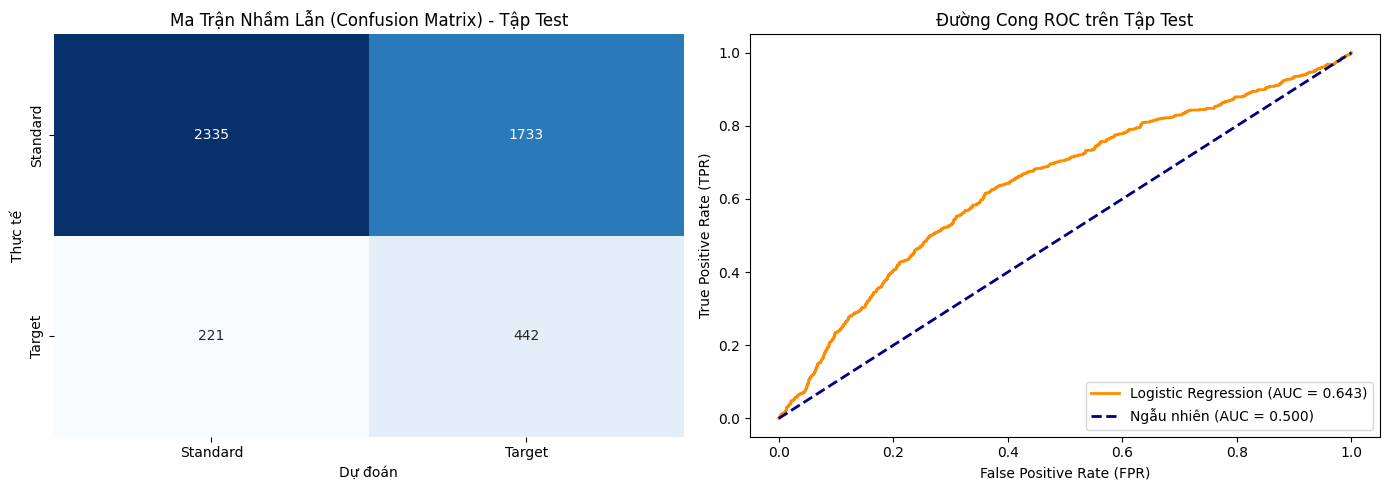

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, 
    balanced_accuracy_score, 
    classification_report, 
    confusion_matrix, 
    roc_auc_score, 
    roc_curve, 
    f1_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Nạp dữ liệu từ file cache đã lưu
train_data = np.load("/kaggle/working/cache/train_features.npz")
val_data   = np.load("/kaggle/working/cache/val_features.npz")
test_data  = np.load("/kaggle/working/cache/test_features.npz")

X_train, y_train = train_data['X'], train_data['y']
X_val, y_val     = val_data['X'], val_data['y']
X_test, y_test   = test_data['X'], test_data['y']

# 2. Chuẩn hóa đặc trưng (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)
print("==> Đã chuẩn hóa dữ liệu thành công!")

# 3. Huấn luyện Mô hình 1: Logistic Regression (Mô hình Tuyến tính Cơ bản)
print("\n[1/2] Đang huấn luyện Logistic Regression...")
model_lr = LogisticRegression(
    C=0.05,
    penalty="l2",
    solver="lbfgs",
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)
model_lr.fit(X_train_scaled, y_train)
print("-> Logistic Regression hoàn thành!")

# 4. Huấn luyện Mô hình 2: Random Forest (Mô hình Cây Quyết định Phi tuyến)
print("\n[2/2] Đang huấn luyện Random Forest Classifier...")
model_rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train_scaled, y_train)
print("-> Random Forest hoàn thành!")

# 5. Dự đoán trên tập TEST (Người 35 - 42)
y_pred_lr = model_lr.predict(X_test_scaled)
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

y_pred_rf = model_rf.predict(X_test_scaled)
y_prob_rf = model_rf.predict_proba(X_test_scaled)[:, 1]

auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# 6. Lập Bảng So Sánh Hiệu Năng 2 Mô Hình
comparison_df = pd.DataFrame([
    {
        "Mô hình": "Logistic Regression (Linear)",
        "Accuracy": round(accuracy_score(y_test, y_pred_lr), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_test, y_pred_lr), 4),
        "F1-Score (Macro)": round(f1_score(y_test, y_pred_lr, average="macro"), 4),
        "ROC-AUC": round(auc_lr, 4),
    },
    {
        "Mô hình": "Random Forest (Tree Ensemble)",
        "Accuracy": round(accuracy_score(y_test, y_pred_rf), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_test, y_pred_rf), 4),
        "F1-Score (Macro)": round(f1_score(y_test, y_pred_rf, average="macro"), 4),
        "ROC-AUC": round(auc_rf, 4),
    }
])

print("\n" + "="*65)
print("      BẢNG SO SÁNH HIỆU NĂNG 2 MÔ HÌNH TRÊN TẬP TEST (35-42)")
print("="*65)
print(comparison_df.to_string(index=False))

# 7. Trực quan hóa so sánh 2 Mô hình
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Ma trận nhầm lẫn - Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Standard", "Target"], yticklabels=["Standard", "Target"], ax=axes[0])
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Dự đoán")
axes[0].set_ylabel("Thực tế")

# Ma trận nhầm lẫn - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Standard", "Target"], yticklabels=["Standard", "Target"], ax=axes[1])
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")

# Đường cong ROC so sánh cả 2 mô hình
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

axes[2].plot(fpr_lr, tpr_lr, color="darkorange", lw=2, label=f"Logistic Reg (AUC = {auc_lr:.3f})")
axes[2].plot(fpr_rf, tpr_rf, color="green", lw=2, label=f"Random Forest (AUC = {auc_rf:.3f})")
axes[2].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Ngẫu nhiên (AUC = 0.500)")
axes[2].set_title("So Sánh Đường Cong ROC (Tập Test)")
axes[2].set_xlabel("False Positive Rate (FPR)")
axes[2].set_ylabel("True Positive Rate (TPR)")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

